# GNSS 中断过桥的入口准入、航速选择与预测安全滤波

主实验在同一座 8 m × 19 m 桥上比较 0.7 m/s ILOS（GNSS 中断）、完整方法（GNSS 中断）和
0.7 m/s ILOS（GNSS 持续可用）。航速选择图显示各候选航速的预测最小裕度及最终选择。
主实验评估包含入口准入和调速在内的整体方案。在线修正和平滑的作用由同入口、同航速消融衡量。

导航误差界沿估计航迹传播，并在 GNSS 融合时按增益更新。入口逐个检查候选航速并选择预测裕度最大者。
在线阶段采用备份策略预测安全滤波，验证带推力变化率限制的平滑候选。解析误差界和盲行距离函数用于条件性诊断。

**命题 2 的拟证明范围**限于通过准入后，在误差界有效、预测覆盖真实闭环、在线递归可行等条件成立时的通行避碰。
入口拒绝后的制动和后撤属于工程应急行为，其停车位置有待独立验证。本 Notebook 给出数值实验。

依赖 NumPy、Matplotlib。执行 Restart Kernel and Run All，图保存到 `figures_revised/`。


## 1. 参数

`bridge_case(cfg, length, width)` 根据桥长和桥宽生成桥的几何：断星区、射流位置与范围、过桥截止时间都随之确定。

In [1]:
import math
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle


@dataclass(frozen=True)
class Config:
    seed: int = 42
    dt: float = 0.02               # plant / navigation step (s)
    control_dt: float = 0.20       # guidance & control step (s)
    duration: float = 90.0
    # bridge (axis along North, centred on East = 0)
    width: float = 4.0             # clear opening between the two walls (m)
    bridge_start: float = 14.0
    bridge_end: float = 26.0
    # GNSS: degraded band of multipath_length on each side of the blackout
    blackout_start: float = 12.5
    blackout_end: float = 28.0
    multipath_length: float = 1.0
    # planned path: approach leg, then a left turn onto the bridge axis
    approach_heading_deg: float = 60.0   # course of the approach leg (from North)
    approach_length: float = 8.0
    turn_north: float = 2.0              # waypoint where the path turns onto the axis
    switch_distance: float = 4.0         # waypoint switching distance (m)
    # Otter-type catamaran
    length: float = 2.0
    beam: float = 1.08
    hull_spacing: float = 0.79           # distance between pontoon centrelines
    pontoon_width: float = 0.29
    # guidance
    speed: float = 0.70              # nominal cruise speed near the bridge
    los_lookahead: float = 4.0
    ilos_kappa: float = 0.5
    # current: mapped background + mapped jet through the opening
    mapped_current_north: float = 0.025
    mapped_current_east: float = 0.090
    jet_center: float = 20.0
    jet_half_length: float = 9.0
    jet_amplitude: float = 0.25
    # declared navigation error bounds (used online and in predictions)
    delta0: float = 0.035
    heading0: float = 0.005
    gyro_bound: float = 0.0008
    speed_error_floor: float = 0.004       # surge speed error bound = floor + ratio * speed
    speed_error_ratio: float = 0.017
    speed_error_lateral: float = 0.006     # sway speed error bound
    water_speed_margin: float = 0.20       # |water speed| <= transit speed + margin
    current_north_error_bound: float = 0.010   # background current, North
    current_east_error_bound: float = 0.015    # background current, East
    jet_amplitude_error_bound: float = 0.22    # extra cross-flow in the jet (map uncertainty)
    actuator_T: float = 0.15
    # predictive safety filter
    prediction_dt: float = 0.02
    smooth_filter: bool = True
    thrust_rate: float = 120.0       # per-thruster command slew limit, N/s
    smoothing_alpha: float = 0.50    # preferred target; reverified before use
    reserve_retention: float = 0.90
    release_hysteresis: float = 0.01 # extra margin to release corrective mode
    gnss_period: float = 0.20
    gate_north: float = 5.0           # admission check point (after the turn)
    retreat_north: float = 2.0
    deadline_seconds: float = 28.0    # from the last GNSS fix at the gate
    map_bound: float = 0.08           # bridge chart registration error
    safety_margin: float = 0.0        # no extra margin beyond the error terms (unified set)
    sample_guard: float = 0.02        # max hull-point lateral speed (0.83 m/s) x 0.02 s prediction step
    min_progress_speed: float = 0.40  # required North ground speed in the rollout
    speed_candidates: tuple = (0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0)  # tried at the gate

    @property
    def degraded_start(self):
        return self.blackout_start - self.multipath_length

    @property
    def degraded_end(self):
        return self.blackout_end + self.multipath_length

    @property
    def jet_gradient_bound(self):
        """max |d shape/dN| times the MAPPED amplitude (the error part is bounded separately)."""
        return abs(self.jet_amplitude) * math.pi / (2*self.jet_half_length)

    def waypoints(self):
        a = math.radians(self.approach_heading_deg)
        p1 = np.array([self.turn_north, 0.0])
        p0 = p1 - self.approach_length*np.array([math.cos(a), math.sin(a)])
        return np.array([p0, p1, [self.degraded_end + 30.0, 0.0]])


@dataclass(frozen=True)
class TruthSpec:
    """Only the simulated world sees these values."""
    jet_amplitude_error: float = 0.20   # unmapped extra cross-flow through the opening
    current_north_bias: float = 0.005
    current_east_bias: float = 0.008
    tide_amplitude: float = 0.004
    tide_frequency: float = 0.050
    wall_shift: float = 0.04             # true walls vs. chart
    initial_cross_track: float = 0.30    # start offset from the approach leg (m)
    initial_heading_error: float = 0.0


def bridge_case(base, length, width=8.0):
    """Bridge of the given clear width and length starting at base.bridge_start.
    The GNSS blackout, the jet through the opening and the transit deadline
    all follow the bridge geometry."""
    start = base.bridge_start
    end = start + length
    blackout_end = end + 2.0
    deadline = (blackout_end + base.multipath_length + 4.0 - base.gate_north)/(0.75*base.speed)
    return replace(base, width=width, bridge_end=end, blackout_end=blackout_end,
                   jet_center=0.5*(start + end), jet_half_length=0.5*length + 3.0,
                   deadline_seconds=deadline)


cfg = Config()
truth_spec = TruthSpec()

## 2. 船模、海流与积分

In [2]:
KPOS, KNEG, ARM = .02216/2, .01289/2, .395
FMIN, FMAX = -.5*13.6*9.81, .5*24.4*9.81


def wrap(angle):
    return (angle + np.pi) % (2*np.pi) - np.pi


def force_to_rpm(F):
    F = np.clip(np.asarray(F, dtype=float), FMIN, FMAX)
    return np.where(F >= 0, 1., -1.)*np.sqrt(np.abs(F)/np.where(F >= 0, KPOS, KNEG))


def allocate(surge, yaw):
    return np.clip(np.array([.5*(surge + yaw/ARM), .5*(surge - yaw/ARM)]), FMIN, FMAX)


class OtterPlant:
    """Planar Otter model (mass, added mass, linear damping, Hoerner cross-flow drag).
    State: [u, v, r, North, East, psi, n_left, n_right]. Only the truth instance
    carries the hydrodynamic mismatch."""
    def __init__(self, cfg, mismatch=False):
        m, mh, rho, L = 80., 55., 1025., 2.
        xg = (55*.2 + 25*.05)/80
        iz = 55*.5**2 + 55*xg*xg + 25*.05**2
        self.M = np.array([[m, 0, 0], [0, m, m*xg], [0, m*xg, iz + m*xg*xg]])
        self.A = np.diag([2.7*rho*(mh/rho)**(5/3)/L**2, 1.5*mh, 1.7*iz])
        self.M += self.A
        self.invM = np.linalg.inv(self.M)
        self.D = np.array([24.4*9.81/(6*.5144), self.M[1, 1], self.M[2, 2]])
        self.m, self.xg = m, xg
        self.draft = (m/rho)/(2*.4*.25*L)
        self.strips = np.linspace(-1, 1, 21)
        table = np.array([[.0108623, 1.966080], [.176606, 1.965730], [.353025, 1.897560], [.451863, 1.787180],
                          [.472838, 1.583740], [.492877, 1.278620], [.493252, 1.210820], [.558473, 1.083560],
                          [.646401, .998631], [.833589, .879590], [.988002, .828415], [1.30807, .759941],
                          [1.63918, .691442], [1.85998, .657076], [2.31288, .630693], [2.59998, .596186],
                          [3.00877, .586846], [3.45075, .585909], [3.7379, .559877], [4.00309, .559315]])
        self.drag_k = .5*rho*self.draft*np.interp(.25/(2*self.draft), table[:, 0], table[:, 1])*.1
        self.mismatch = mismatch
        self.actuator_T = cfg.actuator_T

    def derivative(self, z, F, current, current_dot=None):
        u, v, r, _, _, psi, nl, nr = z
        co, si = np.cos(psi), np.sin(psi)
        uc = co*current[0] + si*current[1]
        vc = -si*current[0] + co*current[1]
        ur, vr = u - uc, v - vc
        p1, p2 = self.A[0, 0]*ur, self.A[1, 1]*vr
        coriolis = np.array([-self.m*r*vr - self.m*r*self.xg*r - p2*r,
                             self.m*r*ur + p1*r,
                             self.m*r*self.xg*ur + p2*ur - p1*vr])
        dragv = vr + self.strips*r
        strips = -self.drag_k*dragv*np.abs(dragv)
        drag = np.array([0., strips.sum(), self.strips @ strips])
        damping = -self.D*np.array([ur, vr, r])
        damping[2] *= 1 + 10*abs(r)
        if self.mismatch:
            damping *= np.array([1.015, 1.025, 1.02])
        n = np.array([nl, nr])
        thrust = np.where(n >= 0, KPOS, KNEG)*n*np.abs(n)
        tau = np.array([thrust.sum(), 0., ARM*(thrust[0] - thrust[1])])
        dc = np.array([r*vc, -r*uc, 0.])
        if current_dot is not None:
            dc[:2] += np.array([co*current_dot[0] + si*current_dot[1], -si*current_dot[0] + co*current_dot[1]])
        dv = dc + self.invM @ (tau + damping + drag - coriolis)
        dn = (force_to_rpm(F) - n)/self.actuator_T
        return np.r_[dv, co*u - si*v, si*u + co*v, r, dn]


def jet_shape(north, c):
    xi = (north - c.jet_center)/c.jet_half_length
    if abs(xi) >= 1.0:
        return 0.0, 0.0
    angle = math.pi*xi
    return 0.5*(1 + math.cos(angle)), -math.pi*math.sin(angle)/(2*c.jet_half_length)


def earth_velocity(z):
    co, si = math.cos(z[5]), math.sin(z[5])
    return np.array([co*z[0] - si*z[1], si*z[0] + co*z[1]])


def body_velocity(earth, heading):
    co, si = math.cos(heading), math.sin(heading)
    return np.array([co*earth[0] + si*earth[1], -si*earth[0] + co*earth[1]])


class CurrentField:
    """Mapped current (truth=None) or true current (truth=TruthSpec)."""
    def __init__(self, cfg, truth=None):
        self.cfg, self.truth = cfg, truth

    def at(self, north, t):
        c = self.cfg
        shape, gradient = jet_shape(north, c)
        north_flow, east_flow = c.mapped_current_north, c.mapped_current_east
        amplitude, time_derivative = c.jet_amplitude, 0.0
        if self.truth is not None:
            d = self.truth
            north_flow += d.current_north_bias
            amplitude += d.jet_amplitude_error
            phase = d.tide_frequency*t
            east_flow += d.current_east_bias + d.tide_amplitude*math.sin(phase)
            time_derivative = d.tide_amplitude*d.tide_frequency*math.cos(phase)
        return np.array([north_flow, east_flow + amplitude*shape]), amplitude*gradient, time_derivative


def propagate(plant, field, z, force, t, dt):
    def derivative(state, instant):
        current, dc_dn, dc_dt = field.at(state[3], instant)
        u_north = math.cos(state[5])*state[0] - math.sin(state[5])*state[1]
        return plant.derivative(state, force, current, (0., dc_dt + dc_dn*u_north))
    first = derivative(z, t)
    out = z + dt*derivative(z + 0.5*dt*first, t + 0.5*dt)
    out[5] = wrap(out[5])
    return out

## 3. 导航器与有界误差传播

GNSS 融合前先传播误差界，再按 `b⁺=(1-K)b⁻+K b_GNSS` 更新；艏向界同样处理。
不再因收到部分融合的定位就把误差界清零。界参数仍需独立物理标定。
闭式函数只用于对照研究方案，未用其替代状态相关误差传播，也未声称已得到解析 U*。


In [3]:
class Sensors:
    """Gyro, propeller rpm and GNSS. GNSS quality depends on the TRUE North position.
    gnss_always=True is a hypothetical reference in which GNSS keeps working under the bridge."""
    def __init__(self, cfg, gnss_always=False):
        self.cfg, self.gnss_always = cfg, gnss_always
        gyro_seed, rpm_seed, gnss_seed = np.random.SeedSequence(cfg.seed).spawn(3)
        self.gyro_rng = np.random.default_rng(gyro_seed)
        self.rpm_rng = np.random.default_rng(rpm_seed)
        self.gnss_rng = np.random.default_rng(gnss_seed)

    def sample(self, truth, gnss_tick):
        c = self.cfg
        packet = {'gyro': truth[2] + .00055 + self.gyro_rng.uniform(-.00025, .00025),
                  'rpm': truth[6:8] + self.rpm_rng.uniform(-.04, .04, 2),
                  'fix': None, 'quality': None}
        if not gnss_tick:
            return packet
        noise = self.gnss_rng.uniform(-1., 1., 5)
        north = truth[3]
        if not self.gnss_always and c.blackout_start <= north <= c.blackout_end:
            packet['quality'] = 'outage'
        elif not self.gnss_always and c.degraded_start <= north <= c.degraded_end:
            packet['quality'] = 'degraded'
        else:
            packet['quality'] = 'good'
            packet['fix'] = (truth[3:5] + .025*noise[:2],
                             earth_velocity(truth) + .008*noise[2:4],
                             wrap(truth[5] + .003*noise[4]))
        return packet


class Navigator:
    """Model-aided dead reckoning (mapped current + Otter model + gyro), corrected by
    GNSS fixes when they are good."""
    def __init__(self, cfg, field):
        self.cfg, self.field = cfg, field
        self.model = OtterPlant(cfg)
        self.z = np.r_[cfg.speed, 0., 0., 0., 0., 0., force_to_rpm([46., 46.])]
        self.previous_gyro = None
        self.last_fix = None
        self.fusion_gain = None
        self.predicted_z = self.z.copy()

    def update(self, packet, t, previous_force, initial=False):
        c = self.cfg
        heading = self.z[5]
        if not initial:
            self.z = propagate(self.model, self.field, self.z, previous_force, t - c.dt, c.dt)
            mean_gyro=packet['gyro'] if self.previous_gyro is None else .5*(self.previous_gyro+packet['gyro'])
            self.z[5] = wrap(heading + c.dt*mean_gyro)
        self.previous_gyro = packet['gyro']
        self.z[2] = packet['gyro']
        self.z[6:8] = packet['rpm']
        self.predicted_z = self.z.copy()
        self.fusion_gain = None
        if packet['quality'] == 'good':
            position, velocity, heading = packet['fix']
            if self.last_fix is None:
                gain = 1.0                       # initialise from the first fix
            else:
                gain = .12 if t - self.last_fix > 1. else .70
            self.z[3:5] += gain*(position - self.z[3:5])
            self.z[5] = wrap(self.z[5] + gain*wrap(heading - self.z[5]))
            self.z[:2] += gain*(body_velocity(velocity, self.z[5]) - self.z[:2])
            self.last_fix = t
            self.fusion_gain = gain
        return self.z.copy()


def jet_shape_max(lo, hi, c):
    """Largest jet shape value for any North position in [lo, hi]."""
    if lo <= c.jet_center <= hi:
        return 1.0
    return max(jet_shape(lo, c)[0], jet_shape(hi, c)[0])


class ErrorBound:
    """Worst-case North/East position-error box grown along the ESTIMATED track
    while no GNSS fix is fused:
      dE/dt <= speed error + |water speed|*heading error + background-current error
               + jet-amplitude error * max shape over the North uncertainty interval
               + mapped jet gradient * North error
    The same law is used online and inside the filter's rollouts."""
    def __init__(self, c, speed=None):
        self.c = c
        self.speed = c.speed if speed is None else speed   # transit speed the bound is valid for
        self.reset()

    def reset(self):
        c = self.c
        self.north, self.east, self.age = c.delta0, c.delta0, 0.
        self.heading = c.heading0

    def copy(self):
        b = ErrorBound(self.c, self.speed)
        b.north, b.east, b.age = self.north, self.east, self.age
        b.heading = self.heading
        return b

    def heading_error(self):
        return self.heading

    def fuse(self, gain):
        # Coordinate-wise bounded GNSS noise from Sensors.sample, NOT covariance.
        self.north = (1-gain)*self.north + gain*.025
        self.east = (1-gain)*self.east + gain*.025
        self.heading = (1-gain)*self.heading + gain*.003
        self.age = 0.

    def step(self, north_est, dt, heading_est=0.):
        c = self.c
        surge_err = c.speed_error_floor + c.speed_error_ratio*self.speed
        heading_part = (self.speed + c.water_speed_margin)*self.heading_error()
        # body-frame speed error projected on North/East (true heading within heading_est +- error)
        s_max = min(1., abs(math.sin(heading_est)) + self.heading_error())
        d_north = surge_err + c.speed_error_lateral*s_max + heading_part + c.current_north_error_bound
        jet = c.jet_amplitude_error_bound*jet_shape_max(north_est - self.north, north_est + self.north, c)
        d_east = (surge_err*s_max + c.speed_error_lateral + heading_part + c.current_east_error_bound
                  + jet + c.jet_gradient_bound*self.north)
        self.north += dt*d_north
        self.east += dt*d_east
        self.age += dt
        self.heading += c.gyro_bound*dt

def closed_form_bound(t, delta0, epsilon_nu, delta_c0, U, psi0, gyro_bias, rho_c):
    """Proposal's scalar envelope; rates must independently bound actual errors.
    This diagnostic is NOT substituted for the spatially varying online box.
    """
    t=np.asarray(t,dtype=float)
    return delta0+(epsilon_nu+delta_c0+U*psi0)*t+.5*(U*gyro_bias+rho_c)*t*t


def closed_form_blind_limit(clearance_budget, delta0, epsilon_nu, delta_c0,
                           U, psi0, gyro_bias, rho_c, min_north_speed):
    """Sufficient time/distance diagnostic for constant guaranteed progress.
    Geometry/heading/control feasibility are separate; this is NOT an optimal U.
    """
    if min_north_speed<=0 or clearance_budget<=delta0:
        return 0.,0.
    a=.5*(U*gyro_bias+rho_c)
    b=epsilon_nu+delta_c0+U*psi0
    budget=clearance_budget-delta0
    if a>0:
        limit=2*budget/(b+math.sqrt(b*b+4*a*budget))
    else:
        limit=budget/b if b>0 else np.inf
    return limit,min_north_speed*limit


## 4. 制导：航路点积分 LOS、备份策略与后撤

In [4]:
class WaypointILOS:
    """Integral LOS on a piecewise-linear path. Cross-track error and the integral
    state use the NAVIGATION ESTIMATE only, so they cannot see unobserved drift."""
    def __init__(self, cfg, field):
        self.cfg, self.field = cfg, field
        self.wp = cfg.waypoints()
        self.k = 0
        self.sigma = 0.
        self.speed = cfg.speed      # transit speed reference (may be raised at the gate)

    def segment(self):
        a, b = self.wp[self.k], self.wp[self.k + 1]
        d = b - a
        return a, math.atan2(d[1], d[0]), float(np.linalg.norm(d))

    def cross_track(self, p):
        a, alpha, length = self.segment()
        rel = p - a
        along = math.cos(alpha)*rel[0] + math.sin(alpha)*rel[1]
        cross = -math.sin(alpha)*rel[0] + math.cos(alpha)*rel[1]
        return along, cross, alpha, length

    def command(self, z, t):
        c = self.cfg
        along, e, alpha, length = self.cross_track(z[3:5])
        if self.k < len(self.wp) - 2 and length - along < c.switch_distance:
            self.k += 1
            self.sigma = 0.
            along, e, alpha, length = self.cross_track(z[3:5])
        self.sigma += c.control_dt*c.los_lookahead*e/((e + c.ilos_kappa*self.sigma)**2 + c.los_lookahead**2)
        course = alpha + math.atan2(-(e + c.ilos_kappa*self.sigma), c.los_lookahead)
        current, _, _ = self.field.at(z[3], t)               # mapped current only
        cross = -math.sin(course)*current[0] + math.cos(course)*current[1]
        crab = math.asin(np.clip(cross/max(.75, self.speed), -.65, .65))
        heading = wrap(course - crab)
        rate_ref = np.clip(1.1*wrap(heading - z[5]), -.22, .22)
        yaw = 82*(rate_ref - z[2]) + 48*z[2]*(1 + 10*abs(z[2]))
        surge = 77.55*self.speed + 65*(self.speed - z[0])
        return allocate(surge, yaw), heading


def backup_command(z, t, c, field, speed=None):
    """Backup policy used by the safety filter: hold the bridge axis (East = 0)
    with a short look-ahead and a faster heading loop."""
    speed = c.speed if speed is None else speed
    course = math.atan2(-z[4], 2.8)
    velocity = earth_velocity(z)
    current, _, _ = field.at(z[3] + 2.0*max(0., velocity[0]), t)
    cross = -math.sin(course)*current[0] + math.cos(course)*current[1]
    crab = math.asin(np.clip(cross/max(.75, speed - current[0]), -.80, .80))
    heading = np.clip(course - crab, -.92, .92)
    rate_ref = np.clip(1.8*wrap(heading - z[5]), -.42, .42)
    yaw = 105*(rate_ref - z[2]) + 48*z[2]*(1 + 10*abs(z[2]))
    surge = 77.55*speed + 65*(speed - z[0])
    return allocate(surge, yaw)


def retreat_command(z, t, c, field):
    """Abort: back off upstream to retreat_north while holding heading 0."""
    north_speed = earth_velocity(z)[0]
    speed_ref = np.clip(.65*(c.retreat_north - z[3]), -.45, .25)
    north_flow = field.at(z[3], t)[0][0]
    surge = 77.55*(speed_ref - north_flow) + 115*(speed_ref - north_speed)
    rate_ref = np.clip(1.1*wrap(0. - z[5]), -.22, .22)
    yaw = 82*(rate_ref - z[2]) + 48*z[2]*(1 + 10*abs(z[2]))
    return allocate(surge, yaw)

## 5. 双体船几何与船体–桥墙间隙

碰撞判定使用两个片体（尖艏）的实际轮廓。

In [5]:
def catamaran_parts(pose, c):
    """Body outline of a small twin-hull USV: two pontoons with pointed bows and
    a deck between them. Returns (pontoons, deck) as arrays in (North, East)."""
    L, w = c.length, c.pontoon_width
    half_spacing = c.hull_spacing/2
    taper = 0.35*L/2
    pontoon = np.array([[-L/2, -w/2], [L/2 - taper, -w/2], [L/2, 0.], [L/2 - taper, w/2], [-L/2, w/2]])
    deck = np.array([[-0.33*L, -half_spacing], [0.22*L, -half_spacing],
                     [0.22*L, half_spacing], [-0.33*L, half_spacing]])
    co, si = math.cos(pose[2]), math.sin(pose[2])
    R = np.array([[co, si], [-si, co]])
    shift = np.array(pose[:2])
    pontoons = [(pontoon + [0., s*half_spacing]) @ R + shift for s in (-1, 1)]
    return pontoons, deck @ R + shift


def polygon_wall_gap(vertices, c, wall_shift):
    """Lateral gap between the part of a polygon inside the bridge and the nearer true wall."""
    north = vertices[:, 0]
    if north.max() < c.bridge_start or north.min() > c.bridge_end:
        return np.nan
    east = [p[1] for p in vertices if c.bridge_start <= p[0] <= c.bridge_end]
    for i, a in enumerate(vertices):
        b = vertices[(i + 1) % len(vertices)]
        for edge in (c.bridge_start, c.bridge_end):
            if min(a[0], b[0]) < edge < max(a[0], b[0]):
                f = (edge - a[0])/(b[0] - a[0])
                east.append(a[1] + f*(b[1] - a[1]))
    return c.width/2 - max(abs(y - wall_shift) for y in east)


def hull_clearance(truth, c, wall_shift):
    pontoons, _ = catamaran_parts((truth[3], truth[4], truth[5]), c)
    gaps = [polygon_wall_gap(p, c, wall_shift) for p in pontoons]
    gaps = [g for g in gaps if np.isfinite(g)]
    return min(gaps) if gaps else np.nan

## 6. 备份预测安全滤波与入口数值认证

平滑候选先由上一条推力和 ILOS 生成；若不满足预测裕度，则向备份动作连续混合。
推力变化率约束同时进入实际候选和整个备份预测。所有动作均需重新验证。
退出修正状态使用裕度滞环。没有使用 HOCBF 不等式；有限候选搜索也不冒充全局最优 QP。
`smooth_filter=False` 保留原局部线性投影/切换算法作对照，但使用同一修正后的导航器和精细预测。


In [6]:
def hull_support(heading, c, heading_error=0.):
    """Half-extents (North, East) of the hull's bounding rectangle, enlarged for a
    heading error bound (|d r/d psi| <= half diagonal)."""
    co, si = abs(math.cos(heading)), abs(math.sin(heading))
    lip = 0.5*math.hypot(c.length, c.beam)
    extra = lip*heading_error
    return (min(lip, 0.5*(c.length*co + c.beam*si) + extra),
            min(lip, 0.5*(c.length*si + c.beam*co) + extra))


def tube_margins(z, bound, c):
    """Predicted lateral wall margin (m) and exit slack for an estimated state z
    and an error box `bound`. wall = +inf when no part of the tube is in the bridge."""
    hx, hy = hull_support(z[5], c, bound.heading_error())
    pad_n = hx + bound.north + c.map_bound + c.sample_guard
    stern, bow = z[3] - pad_n, z[3] + pad_n
    wall = np.inf
    if stern <= c.bridge_end and bow >= c.bridge_start:
        wall = (c.width/2 - abs(z[4]) - hy - bound.east - c.map_bound - c.sample_guard - c.safety_margin)
    return wall, stern - c.degraded_end


class PredictiveSafetyFilter:
    """Backup-based predictive safety filter. A candidate thrust is accepted only if,
    applying it for one control step and then the backup policy, the predicted
    estimate stays inside the shrinking safe tube, keeps North progress, and the
    conservative stern leaves the degraded zone before the deadline."""
    def __init__(self, c, field):
        self.c, self.field = c, field
        self.model = OtterPlant(c)
        self.deadline = None
        self.speed = c.speed
        self.previous_force = None
        self.correcting = False
        self.trace = []

    def limit_force(self, candidate, previous):
        candidate=np.clip(candidate,FMIN,FMAX)
        if not self.c.smooth_filter or previous is None:
            return candidate
        delta=self.c.thrust_rate*self.c.control_dt
        return np.clip(candidate,previous-delta,previous+delta)

    def rollout(self, z0, bound0, t, first=None):
        c=self.c
        z,bound=z0.copy(),bound0.copy()
        bound.speed=self.speed
        wall,exit_slack=tube_margins(z,bound,c)
        worst,progress_ok=wall,True
        nsub=max(1,int(math.ceil(c.control_dt/c.prediction_dt)))
        h=c.control_dt/nsub
        previous=None if self.previous_force is None else self.previous_force.copy()
        for i in range(max(0,int(math.ceil((self.deadline-t)/c.control_dt)))):
            ts=t+i*c.control_dt
            raw=first if i==0 and first is not None else backup_command(z,ts,c,self.field,self.speed)
            force=self.limit_force(raw,previous)
            previous=force.copy()
            for sub in range(nsub):
                instant=ts+(sub+1)*h
                if instant>self.deadline+1e-9:
                    return min(worst,exit_slack),False
                z=propagate(self.model,self.field,z,force,ts+sub*h,h)
                bound.step(z[3],h,z[5])
                # GNSS is fused only at actual measurement times and only while
                # the complete North uncertainty interval is before degradation.
                gnss_tick=abs(instant/c.gnss_period-round(instant/c.gnss_period))<1e-7
                if gnss_tick and z[3]+bound.north<c.degraded_start:
                    bound.fuse(.70)
                wall,exit_slack=tube_margins(z,bound,c)
                worst=min(worst,wall)
                progress_ok &= earth_velocity(z)[0]>=c.min_progress_speed
                if exit_slack>=0.:
                    return worst,bool(progress_ok)
        return min(worst,exit_slack),False

    def admit(self, z, bound, t, last_fix):
        """Try every candidate transit speed; keep the certified one with the largest margin.
        Returns (admitted, margin, speed, {speed: margin})."""
        self.deadline = last_fix + self.c.deadline_seconds
        table, best = {}, None
        for U in self.c.speed_candidates:
            self.speed = U
            margin, ok = self.rollout(z, bound, t)
            table[U] = margin if ok else -np.inf
            if ok and margin >= 0. and (best is None or margin > table[best]):
                best = U
        if best is None:
            self.speed = self.c.speed
            finite = [m for m in table.values() if np.isfinite(m)]
            return False, (max(finite) if finite else -np.inf), None, table
        self.speed = best
        return True, table[best], best, table

    def apply_legacy(self, z, bound, t, nominal):
        b0, ok0 = self.rollout(z, bound, t)
        bn, okn = self.rollout(z, bound, t, nominal)
        reserve = max(0., b0)
        target = max((1 - .5*self.c.control_dt)*reserve, min(.20, reserve))
        if okn and bn >= target:
            return nominal, 'nominal', bn
        eps, grad = .8, np.zeros(2)
        for j in range(2):
            shifted = nominal.copy()
            shifted[j] += eps if shifted[j] <= FMAX - eps else -eps
            grad[j] = (self.rollout(z, bound, t, shifted)[0] - bn)/(shifted[j] - nominal[j])
        if np.linalg.norm(grad) > 1e-10:
            # local linearised projection (candidate only; full rollout rechecks):  min ||F - F_nom||^2  s.t.  bn + grad.(F - F_nom) >= target
            gap = target - bn
            F = np.clip(nominal + grad*gap/np.dot(grad, grad), FMIN, FMAX)
            bv, ok = self.rollout(z, bound, t, F)
            if ok and bv >= target:
                return F, 'qp', bv
        if ok0 and b0 >= 0.:
            return backup_command(z, t, self.c, self.field, self.speed), 'backup', b0
        return None, 'no verified action', b0

    def apply(self, z, bound, t, nominal):
        if not self.c.smooth_filter:
            chosen,mode,margin=self.apply_legacy(z,bound,t,nominal)
            if chosen is not None:self.previous_force=chosen.copy()
            return chosen,mode,margin
        backup=self.limit_force(backup_command(z,t,self.c,self.field,self.speed),self.previous_force)
        b0,ok0=self.rollout(z,bound,t,backup)
        target=max(0.,self.c.reserve_retention*max(0.,b0))
        preferred=self.limit_force(nominal if self.previous_force is None else
            self.previous_force+self.c.smoothing_alpha*(nominal-self.previous_force),self.previous_force)
        bn,okn=self.rollout(z,bound,t,preferred)
        release=target+(self.c.release_hysteresis if self.correcting else 0.)
        selected,mode,best=None,'no verified action',b0
        if okn and bn>=release:
            selected,mode,best=preferred,'smooth_nominal',bn
            self.correcting=False
        else:
            # Ordered continuous blends. Every actual target is rate limited
            # AND checked; no unverified post-processing of a certified action.
            for alpha in (.25,.50,.75):
                trial=self.limit_force((1-alpha)*preferred+alpha*backup,self.previous_force)
                bt,ok=self.rollout(z,bound,t,trial)
                if ok and bt>=target:
                    selected,mode,best=trial,'blend',bt
                    break
            if selected is None and ok0 and b0>=0.:
                selected,mode,best=backup,'backup',b0
            self.correcting=True
        self.trace.append(dict(t=t,nominal_margin=bn,backup_margin=b0,
                               selected_margin=best,target=target,mode=mode))
        if selected is not None:self.previous_force=selected.copy()
        return selected,mode,best


## 7. 闭环仿真

In [7]:
def run_case(c, truth_spec, strategy="ilos", gnss_always=False, fixed_gate_speed=None, bypass_filter=False):
    """Closed loop: true plant + sensors -> navigator -> guidance (+ safety filter) -> thrusters.
    strategy: "ilos"     waypoint ILOS only
              "filtered" waypoint ILOS as nominal input + predictive safety filter
    The controller and the filter never read the true state."""
    steps_per_control = int(round(c.control_dt/c.dt))
    wp = c.waypoints()
    a = math.radians(c.approach_heading_deg)
    start = wp[0] + truth_spec.initial_cross_track*np.array([-math.sin(a), math.cos(a)])
    truth = np.r_[c.speed, 0., 0., start, a + truth_spec.initial_heading_error, force_to_rpm([46., 46.])]
    plant = OtterPlant(c, mismatch=True)
    true_current = CurrentField(c, truth=truth_spec)
    mapped_current = CurrentField(c)
    sensors = Sensors(c, gnss_always=gnss_always)
    nav = Navigator(c, mapped_current)
    guide = WaypointILOS(c, mapped_current)
    guard = PredictiveSafetyFilter(c, mapped_current)
    bound = ErrorBound(c)
    force, quality, phase, mode, margin = allocate(2*46., 0.), 'good', 'approach', 'ILOS', np.nan
    ev = dict(impact_time=np.nan, completed=False, gate_time=np.nan, admitted=None,
              entry_margin=np.nan, transit_speed=c.speed, speed_table={}, retreated=False, failure='')
    rows, settle_ticks = [], 0

    for i in range(round(c.duration/c.dt) + 1):
        t = i*c.dt
        tick = i % steps_per_control == 0
        packet = sensors.sample(truth, gnss_tick=tick)
        if packet['quality'] is not None:
            quality = packet['quality']
        before = nav.last_fix
        z = nav.update(packet, t, force, initial=(i == 0))
        if i>0:
            bound.step(nav.predicted_z[3],c.dt,nav.predicted_z[5])
        if nav.last_fix != before:
            bound.fuse(nav.fusion_gain)

        if tick:
            guard.previous_force=force.copy()
            margin = np.nan
            if (strategy == "filtered" or bypass_filter) and phase == 'approach' and z[3] >= c.gate_north:
                ev['gate_time'] = t
                if bypass_filter:
                    speed_g = c.speed if fixed_gate_speed is None else fixed_gate_speed
                    ev['transit_speed'] = speed_g
                    guide.speed = speed_g
                    bound.speed = speed_g
                    phase = 'unfiltered_transit'
                else:
                    if fixed_gate_speed is None:
                        ok, margin_g, speed_g, table = guard.admit(z, bound, t, nav.last_fix)
                    else:
                        guard.deadline = nav.last_fix + c.deadline_seconds
                        guard.speed = fixed_gate_speed
                        margin_g, progress = guard.rollout(z, bound, t)
                        ok = bool(progress and margin_g >= 0.)
                        speed_g = fixed_gate_speed if ok else None
                        table = {fixed_gate_speed: margin_g if progress else -np.inf}
                    ev.update(admitted=ok, entry_margin=margin_g, speed_table=table)
                    if ok:
                        ev['transit_speed'] = speed_g
                        guide.speed = speed_g
                        bound.speed = speed_g
                    phase = 'transit' if ok else 'abort' 

            if phase == 'transit':
                _, exit_slack = tube_margins(z, bound, c)
                if exit_slack >= 0.:
                    phase = 'exit'
            if phase == 'abort':
                if earth_velocity(z)[0] > .08 and not ev['retreated']:
                    force, mode = allocate(2*FMIN, 0.), 'brake'
                else:
                    ev['retreated'] = True
                    force, mode = retreat_command(z, t, c, mapped_current), 'retreat'
                    settled = abs(z[3] - c.retreat_north) <= .25 and abs(earth_velocity(z)[0]) <= .12
                    settle_ticks = settle_ticks + 1 if settled else 0
            else:
                nominal, _ = guide.command(z, t)
                force, mode = nominal, 'ILOS'
                if phase == 'transit' and not bypass_filter:
                    selected, mode, margin = guard.apply(z, bound, t, nominal)
                    if selected is None:
                        ev['failure'] = 'no verified action'
                        # Stop the experiment; do not silently execute an
                        # action that has failed the current verification.
                        break
                    force = selected
                elif phase == 'exit' and c.smooth_filter and not bypass_filter:
                    force=guard.limit_force(force,guard.previous_force)

        clearance = hull_clearance(truth, c, truth_spec.wall_shift)
        rows.append(dict(t=t, truth=truth.copy(), estimate=z.copy(), F=force.copy(), quality=quality,
                         clearance=clearance, mode=mode, tick=tick, margin=margin,
                         bound=np.array([bound.north, bound.east]), heading_bound=bound.heading_error()))
        if np.isfinite(clearance) and clearance <= 0.:
            ev['impact_time'] = t
            break
        if truth[3] - c.length/2 > c.degraded_end + 3.:
            ev['completed'] = True
            break
        if phase == 'abort' and settle_ticks*c.control_dt >= 1.0:
            break
        truth = propagate(plant, true_current, truth, force, t, c.dt)

    data = {k: np.array([r[k] for r in rows]) for k in rows[0]}
    data.update(ev)
    data["filter_trace"]=guard.trace
    return data


def outcome(d):
    if d['failure']:
        return 'verification lost: '+d['failure']
    if np.isfinite(d['impact_time']):
        return f"wall contact at t = {d['impact_time']:.2f} s"
    if d['admitted'] is False:
        return f"entry not certified (gate margin {d['entry_margin']:+.2f} m) -> braked and retreated"
    if d['completed']:
        extra = (f" (certified at {d['transit_speed']:.1f} m/s, gate margin {d['entry_margin']:+.2f} m)"
                 if np.isfinite(d['entry_margin']) else "")
        return "passed the bridge" + extra
    return "simulation ended"

def thrust_metrics(d):
    # Same gate-to-exit window; approach braking is reported separately.
    tick=d['tick'] & (d['t']>=d['gate_time']) if np.isfinite(d['gate_time']) else d['tick']
    force=d['F'][tick]
    change=np.diff(force,axis=0)
    return dict(total_variation_N=float(np.abs(change).sum()),
                max_step_N=float(np.abs(change).max()) if change.size else 0.,
                rms_step_N=float(np.sqrt(np.mean(change**2))) if change.size else 0.)


## 8. 主实验与同航速消融

主实验比较断星 0.7 m/s ILOS、完整方法和 GNSS 持续可用的 0.7 m/s ILOS。
对比包含入口调速与在线控制的共同作用。

消融实验让无滤波组和原切换组使用完整方法所选航速。无滤波组在相同入口直接设置该参考航速，
全程按 ILOS 控制。原切换组保留自身的预测准入。推力总变差统计从入口控制时刻至仿真结束。

默认算例中，完整方法的主要作用是入口准入与航速选择。同航速消融量化了在线修正的有限收益及其推力代价。


In [8]:
BRIDGE = bridge_case(cfg,length=19.0,width=8.0)
c=BRIDGE
ilos_outage = run_case(c, truth_spec, "ilos")
ilos_gnss = run_case(c, truth_spec, "ilos", gnss_always=True)
auto=run_case(c,truth_spec,"filtered")
main_runs={"ilos_outage":ilos_outage,"filtered":auto,"ilos_gnss":ilos_gnss}
print("Main experiment (same bridge)")
for name,d in main_runs.items():
    clearance=np.nanmin(d["clearance"]) if np.isfinite(d["clearance"]).any() else np.nan
    print(f"{name}: {outcome(d)}, minimum clearance {clearance:.3f} m")

U=auto["transit_speed"] if auto["admitted"] else 1.6
runs={"filtered":auto,
      "off":run_case(c,truth_spec,"filtered",fixed_gate_speed=U,bypass_filter=True),
      "legacy":run_case(replace(c,smooth_filter=False),truth_spec,"filtered",fixed_gate_speed=U)}
if auto["admitted"]:
    gi=int(round(auto["gate_time"]/c.dt))
    for name in ("off","legacy"):
        np.testing.assert_array_equal(auto["truth"][:gi+1],runs[name]["truth"][:gi+1])
        np.testing.assert_array_equal(auto["estimate"][:gi+1],runs[name]["estimate"][:gi+1])
print(f"\nMatched-speed ablation ({U:.1f} m/s at the gate)")
for name,d in runs.items():
    clearance=np.nanmin(d["clearance"]) if np.isfinite(d["clearance"]).any() else np.nan
    print(name,outcome(d),"minimum clearance",clearance,"thrust metrics",thrust_metrics(d))
off = runs["off"]
if auto["completed"] and off["completed"]:
    gap_gain = np.nanmin(auto["clearance"]) - np.nanmin(off["clearance"])
    off_tv = thrust_metrics(off)["total_variation_N"]
    print(f"Online correction vs. ILOS at matched speed: clearance change {gap_gain:+.3f} m")
    if off_tv > 0:
        print(f"Thrust total variation ratio: {thrust_metrics(auto)['total_variation_N']/off_tv:.2f}x")


Main experiment (same bridge)
ilos_outage: wall contact at t = 48.64 s, minimum clearance -0.002 m
filtered: passed the bridge (certified at 1.6 m/s, gate margin +0.39 m), minimum clearance 1.314 m
ilos_gnss: passed the bridge, minimum clearance 2.400 m



Matched-speed ablation (1.6 m/s at the gate)
filtered passed the bridge (certified at 1.6 m/s, gate margin +0.39 m) minimum clearance 1.3141756677738785 thrust metrics {'total_variation_N': 878.7721977965308, 'max_step_N': 23.281031093519687, 'rms_step_N': 5.56917657918528}
off passed the bridge minimum clearance 1.3431997279696914 thrust metrics {'total_variation_N': 534.6582603690592, 'max_step_N': 29.43576303522748, 'rms_step_N': 3.8505155654523215}
legacy passed the bridge (certified at 1.6 m/s, gate margin +0.41 m) minimum clearance 1.453753698131551 thrust metrics {'total_variation_N': 2133.329774235366, 'max_step_N': 68.04944313629687, 'rms_step_N': 19.559952951321844}
Online correction vs. ILOS at matched speed: clearance change -0.029 m
Thrust total variation ratio: 1.64x


## 9. 主实验、入口航速选择与消融图

主实验图展示轨迹和真实船体间隙。入口图显示各离散候选航速的预测裕度与选中的航速。
消融图展示同航速下的实际间隙、推力指令和 GNSS 恢复前后的横向误差界。


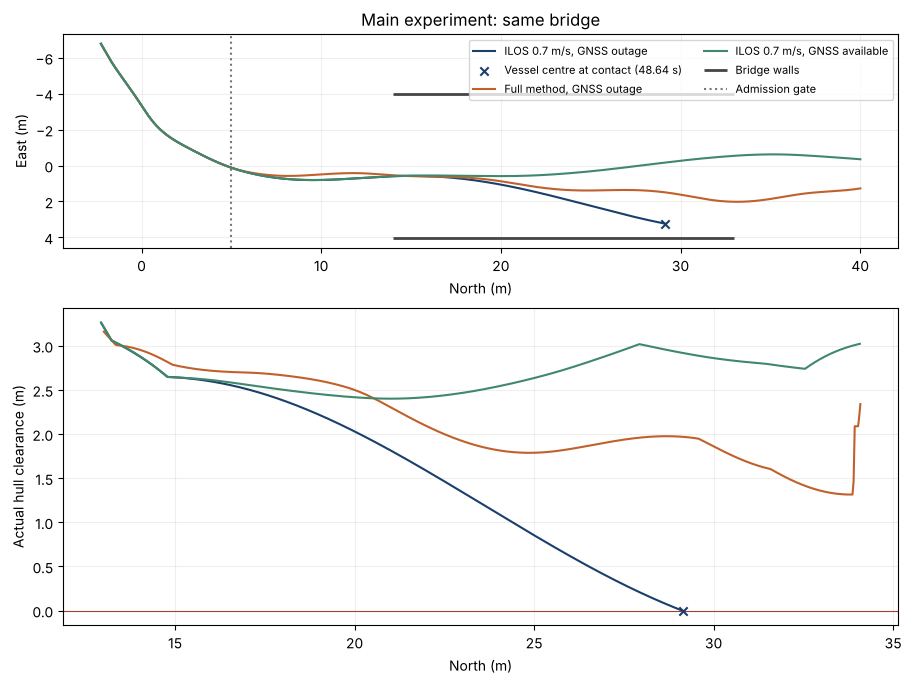

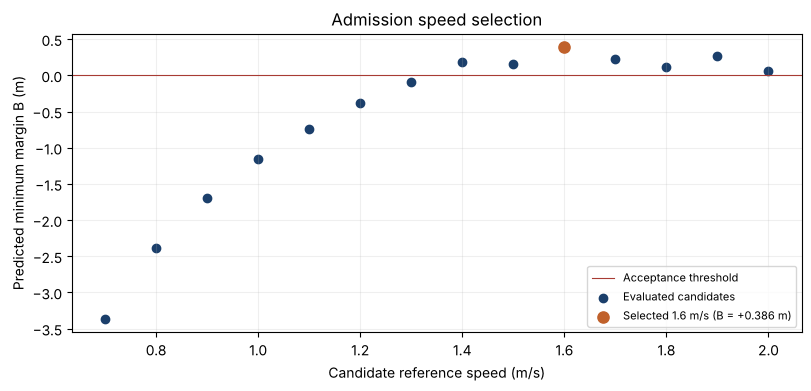

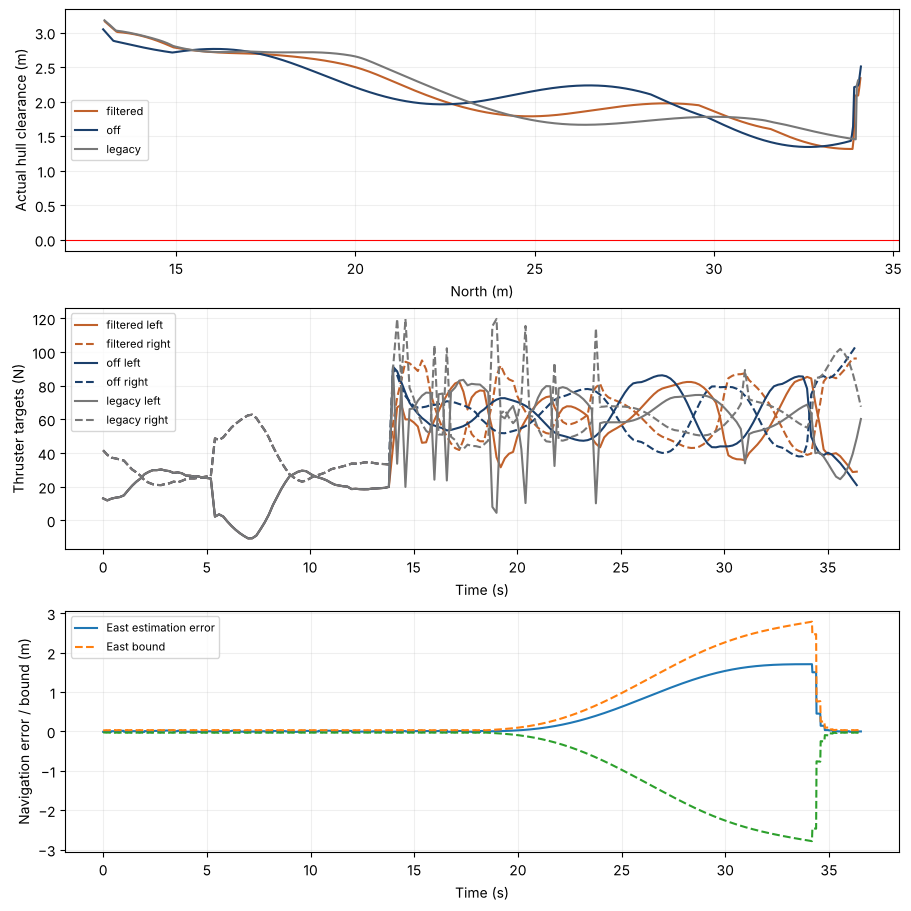

In [9]:
FIG_DIR=Path("figures_revised")
FIG_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIG_DIR/f"{name}.png", dpi=220)
    fig.savefig(FIG_DIR/f"{name}.pdf")
    plt.show()

fig, (track_ax, gap_ax) = plt.subplots(2, 1, figsize=(9, 7), layout="constrained")
main_styles = {
    "ilos_outage": ("ILOS 0.7 m/s, GNSS outage", "#1b3f6b"),
    "filtered": ("Full method, GNSS outage", "#c0612b"),
    "ilos_gnss": ("ILOS 0.7 m/s, GNSS available", "#40886c"),
}
for name, data in main_runs.items():
    label, color = main_styles[name]
    north, east = data["truth"][:, 3:5].T
    track_ax.plot(north, east, label=label, color=color)
    gap_ax.plot(north, data["clearance"], color=color)
    if np.isfinite(data["impact_time"]):
        track_ax.scatter(north[-1], east[-1], color=color, marker="x", zorder=5,
                         label=f"Vessel centre at contact ({data['impact_time']:.2f} s)")
        gap_ax.scatter(north[-1], data["clearance"][-1], color=color, marker="x", zorder=5)
walls = [truth_spec.wall_shift - c.width/2, truth_spec.wall_shift + c.width/2]
track_ax.hlines(walls, c.bridge_start, c.bridge_end, color="#444444", lw=2, label="Bridge walls")
track_ax.axvline(c.gate_north, color="#777777", ls=":", label="Admission gate")
track_ax.set(xlabel="North (m)", ylabel="East (m)", title="Main experiment: same bridge")
track_ax.set_aspect("equal")
track_ax.invert_yaxis()
track_ax.legend(fontsize=8, ncols=2)
gap_ax.axhline(0, color="#a83b34", lw=.8)
gap_ax.set(xlabel="North (m)", ylabel="Actual hull clearance (m)")
for ax in (track_ax, gap_ax):
    ax.grid(alpha=.2)
save_figure(fig, "main_experiment")

fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
table = auto["speed_table"]
speeds = np.array(sorted(table))
margins = np.array([table[speed] for speed in speeds])
finite = np.isfinite(margins)
ax.axhline(0, color="#a83b34", lw=.8, label="Acceptance threshold")
ax.scatter(speeds[finite], margins[finite], color="#1b3f6b", label="Evaluated candidates")
if np.any(~finite):
    ax.scatter(speeds[~finite], np.full(np.count_nonzero(~finite), .05),
               transform=ax.get_xaxis_transform(), marker="x", color="#a83b34",
               label="Failed progress or deadline check")
if auto["admitted"]:
    selected_speed = auto["transit_speed"]
    selected_margin = table[selected_speed]
    ax.scatter(selected_speed, selected_margin, color="#c0612b", s=65, zorder=5,
               label=f"Selected {selected_speed:.1f} m/s (B = {selected_margin:+.3f} m)")
ax.set(xlabel="Candidate reference speed (m/s)", ylabel="Predicted minimum margin B (m)",
       title="Admission speed selection")
ax.grid(alpha=.2)
ax.legend(fontsize=8, loc="lower right")
save_figure(fig, "gate_speed_selection")

colors={"filtered":"#c0612b","off":"#1b3f6b","legacy":"#777777"}
fig,axes=plt.subplots(3,1,figsize=(9,9),layout="constrained")
for name,d in runs.items():
    axes[0].plot(d["truth"][:,3],d["clearance"],label=name,color=colors[name])
    mask=d["tick"]
    axes[1].plot(d["t"][mask],d["F"][mask,0],label=name+" left",color=colors[name])
    axes[1].plot(d["t"][mask],d["F"][mask,1],ls="--",label=name+" right",color=colors[name])
d=runs["filtered"]
axes[2].plot(d["t"],d["truth"][:,4]-d["estimate"][:,4],label="East estimation error")
axes[2].plot(d["t"],d["bound"][:,1],ls="--",label="East bound")
axes[2].plot(d["t"],-d["bound"][:,1],ls="--")
axes[0].axhline(0,color="red",lw=.8)
axes[0].set(xlabel="North (m)",ylabel="Actual hull clearance (m)")
axes[1].set(xlabel="Time (s)",ylabel="Thruster targets (N)")
axes[2].set(xlabel="Time (s)",ylabel="Navigation error / bound (m)")
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
save_figure(fig, "comparison")
